In [3]:
%load_ext autoreload
%autoreload 2

from fraudshield.load_data import get_train_test

X_train, X_test, y_train, y_test = get_train_test()

Missing values: 0
Removed 1081 duplicates
Train: (226980, 31) fraud = 0.167%
Test : (56746, 31) fraud = 0.167%


In [6]:
from fraudshield.load_data import make_preprocessor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline = Pipeline([
    ("prep", make_preprocessor()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000))
])

lr_plain = Pipeline([
    ("prep", make_preprocessor()),
    ("model", LogisticRegression(max_iter=1000))
])

baseline.fit(X_train, y_train)
lr_plain.fit(X_train, y_train)

print("Both models trained")

Both models trained


In [7]:
from fraudshield.evaluation import evaluate_model, compare_results

evaluate_model("LR balanced", baseline, X_test, y_test)
evaluate_model("LR plain", lr_plain, X_test, y_test)

compare_results()

=== LR balanced (threshold = 0.5) ===
              precision    recall  f1-score   support

           0     0.9998    0.9750    0.9872     56651
           1     0.0554    0.8737    0.1041        95

    accuracy                         0.9748     56746
   macro avg     0.5276    0.9243    0.5457     56746
weighted avg     0.9982    0.9748    0.9858     56746

[[55235  1416]
 [   12    83]]
ROC-AUC: 0.9685
PR-AUC : 0.6703
=== LR plain (threshold = 0.5) ===
              precision    recall  f1-score   support

           0     0.9993    0.9998    0.9996     56651
           1     0.8636    0.6000    0.7081        95

    accuracy                         0.9992     56746
   macro avg     0.9315    0.7999    0.8538     56746
weighted avg     0.9991    0.9992    0.9991     56746

[[56642     9]
 [   38    57]]
ROC-AUC: 0.9598
PR-AUC : 0.6927


,PR-AUC,ROC-AUC,Precision,Recall,F1,TP,FP,FN,TN,Threshold
LR plain,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.5
LR balanced,0.6703,0.9685,0.0554,0.8737,0.1041,83.0,1416.0,12.0,55235.0,0.5


In [13]:
for t in [0.5, 0.2, 0.1, 0.05]:
    evaluate_model(f"LR plain @{t}", lr_plain, X_test, y_test, threshold=t, show=False)

compare_results()

,PR-AUC,ROC-AUC,Precision,Recall,F1,TP,FP,FN,TN,Threshold
CatBoost plain,0.8265,0.9825,0.9714,0.7158,0.8242,68.0,2.0,27.0,56649.0,0.50
XGB plain,0.8053,0.9729,0.9571,0.7053,0.8121,67.0,3.0,28.0,56648.0,0.50
LR plain,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.50
LR plain @0.5,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.50
LR plain @0.1,0.6927,0.9598,0.8434,0.7368,0.7865,70.0,13.0,25.0,56638.0,0.10
LR plain @0.2,0.6927,0.9598,0.8354,0.6947,0.7586,66.0,13.0,29.0,56638.0,0.20
LR plain @0.05,0.6927,0.9598,0.7629,0.7789,0.7708,74.0,23.0,21.0,56628.0,0.05
LR balanced,0.6703,0.9685,0.0554,0.8737,0.1041,83.0,1416.0,12.0,55235.0,0.50


LR plain precision at recall >= 0.874: 0.010539367637941723


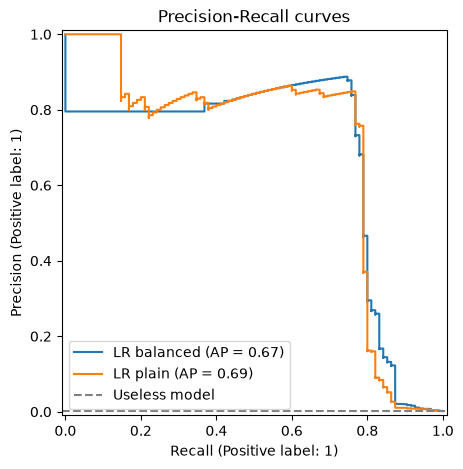

In [9]:
from sklearn.metrics import precision_recall_curve
from fraudshield.evaluation import plot_pr_curves

# What precision does LR plain get when it reaches the recall of LR balanced (0.874)?
y_proba_plain = lr_plain.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, y_proba_plain)
print("LR plain precision at recall >= 0.874:", prec[rec >= 0.8737].max())

plot_pr_curves({"LR balanced": baseline, "LR plain": lr_plain},
               X_test, y_test, save_path="../reports/figures/pr_curves.png")

In [12]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=4,
    eval_metric="aucpr",
    n_jobs=-1,
    random_state=42,
)
xgb.fit(X_train, y_train)

evaluate_model("XGB plain", xgb, X_test, y_test)
compare_results()


=== XGB plain (threshold = 0.5) ===
              precision    recall  f1-score   support

           0     0.9995    0.9999    0.9997     56651
           1     0.9571    0.7053    0.8121        95

    accuracy                         0.9995     56746
   macro avg     0.9783    0.8526    0.9059     56746
weighted avg     0.9994    0.9995    0.9994     56746

[[56648     3]
 [   28    67]]
ROC-AUC: 0.9729
PR-AUC : 0.8053


,PR-AUC,ROC-AUC,Precision,Recall,F1,TP,FP,FN,TN,Threshold
CatBoost plain,0.8265,0.9825,0.9714,0.7158,0.8242,68.0,2.0,27.0,56649.0,0.5
XGB plain,0.8053,0.9729,0.9571,0.7053,0.8121,67.0,3.0,28.0,56648.0,0.5
LR plain,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.5
LR balanced,0.6703,0.9685,0.0554,0.8737,0.1041,83.0,1416.0,12.0,55235.0,0.5


In [14]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {"LR balanced": baseline, "LR plain": lr_plain, "XGB plain": xgb}

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="average_precision")
    print(f"{name}: PR-AUC = {scores.mean():.3f} ± {scores.std():.3f}")

LR balanced: PR-AUC = 0.754 ± 0.027
LR plain: PR-AUC = 0.757 ± 0.030
XGB plain: PR-AUC = 0.842 ± 0.027


In [15]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42,
)
rf.fit(X_train, y_train)

evaluate_model("RF plain", rf, X_test, y_test, show=False)

scores = cross_val_score(rf, X_train, y_train, cv=cv, scoring="average_precision")
print(f"RF plain: PR-AUC = {scores.mean():.3f} ± {scores.std():.3f}")

compare_results()

KeyboardInterrupt: 

In [16]:
from catboost import CatBoostClassifier

cat = CatBoostClassifier(
    iterations=300,
    learning_rate=0.1,
    depth=6,
    eval_metric="PRAUC",
    random_seed=42,
    thread_count=-1,
    verbose=0,
)
cat.fit(X_train, y_train)

evaluate_model("CatBoost plain", cat, X_test, y_test, show=False)

scores = cross_val_score(cat, X_train, y_train, cv=cv, scoring="average_precision")
print(f"CatBoost plain: PR-AUC = {scores.mean():.3f} ± {scores.std():.3f}")

compare_results()

CatBoost plain: PR-AUC = 0.850 ± 0.030


,PR-AUC,ROC-AUC,Precision,Recall,F1,TP,FP,FN,TN,Threshold
CatBoost plain,0.8265,0.9825,0.9714,0.7158,0.8242,68.0,2.0,27.0,56649.0,0.50
XGB plain,0.8053,0.9729,0.9571,0.7053,0.8121,67.0,3.0,28.0,56648.0,0.50
LR plain,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.50
LR plain @0.5,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.50
LR plain @0.1,0.6927,0.9598,0.8434,0.7368,0.7865,70.0,13.0,25.0,56638.0,0.10
LR plain @0.2,0.6927,0.9598,0.8354,0.6947,0.7586,66.0,13.0,29.0,56638.0,0.20
LR plain @0.05,0.6927,0.9598,0.7629,0.7789,0.7708,74.0,23.0,21.0,56628.0,0.05
LR balanced,0.6703,0.9685,0.0554,0.8737,0.1041,83.0,1416.0,12.0,55235.0,0.50


In [17]:
import numpy as np
from sklearn.model_selection import cross_val_predict

# 1. Out-of-fold probabilities (training data only)
oof_proba = cross_val_predict(cat, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
y_arr = y_train.to_numpy()

# 2. Costs: assumptions, you can change them
COST_FN = 120   # a missed fraud costs about its amount
COST_FP = 5     # a false alarm costs investigation time

def cost_at(t):
    pred = oof_proba >= t
    fn = ((~pred) & (y_arr == 1)).sum()
    fp = (pred & (y_arr == 0)).sum()
    return fn * COST_FN + fp * COST_FP

# 3. Try many thresholds, keep the cheapest
thresholds = np.linspace(0.01, 0.99, 99)
costs = [cost_at(t) for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]

pred = oof_proba >= best_t
tp = (pred & (y_arr == 1)).sum()
print("Best threshold      :", round(best_t, 2))
print("Cost at 0.5         :", cost_at(0.5))
print("Cost at best        :", min(costs))
print("Precision at best   :", round(tp / pred.sum(), 3))
print("Recall at best      :", round(tp / (y_arr == 1).sum(), 3))

Best threshold      : 0.11
Cost at 0.5         : 9455
Cost at best        : 7395
Precision at best   : 0.891
Recall at best      : 0.841


In [18]:
from fraudshield.evaluation import results

final_name = f"CatBoost @{best_t:.2f}"
evaluate_model(final_name, cat, X_test, y_test, threshold=best_t)

r = results[final_name]
print("Test cost:", r["FN"] * COST_FN + r["FP"] * COST_FP)

compare_results()

=== CatBoost @0.11 (threshold = 0.11) ===
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     56651
           1     0.9250    0.7789    0.8457        95

    accuracy                         0.9995     56746
   macro avg     0.9623    0.8894    0.9227     56746
weighted avg     0.9995    0.9995    0.9995     56746

[[56645     6]
 [   21    74]]
ROC-AUC: 0.9825
PR-AUC : 0.8265
Test cost: 2550


,PR-AUC,ROC-AUC,Precision,Recall,F1,TP,FP,FN,TN,Threshold
CatBoost plain,0.8265,0.9825,0.9714,0.7158,0.8242,68.0,2.0,27.0,56649.0,0.50
CatBoost @0.11,0.8265,0.9825,0.9250,0.7789,0.8457,74.0,6.0,21.0,56645.0,0.11
XGB plain,0.8053,0.9729,0.9571,0.7053,0.8121,67.0,3.0,28.0,56648.0,0.50
LR plain @0.5,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.50
LR plain,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.50
LR plain @0.1,0.6927,0.9598,0.8434,0.7368,0.7865,70.0,13.0,25.0,56638.0,0.10
LR plain @0.2,0.6927,0.9598,0.8354,0.6947,0.7586,66.0,13.0,29.0,56638.0,0.20
LR plain @0.05,0.6927,0.9598,0.7629,0.7789,0.7708,74.0,23.0,21.0,56628.0,0.05
LR balanced,0.6703,0.9685,0.0554,0.8737,0.1041,83.0,1416.0,12.0,55235.0,0.50


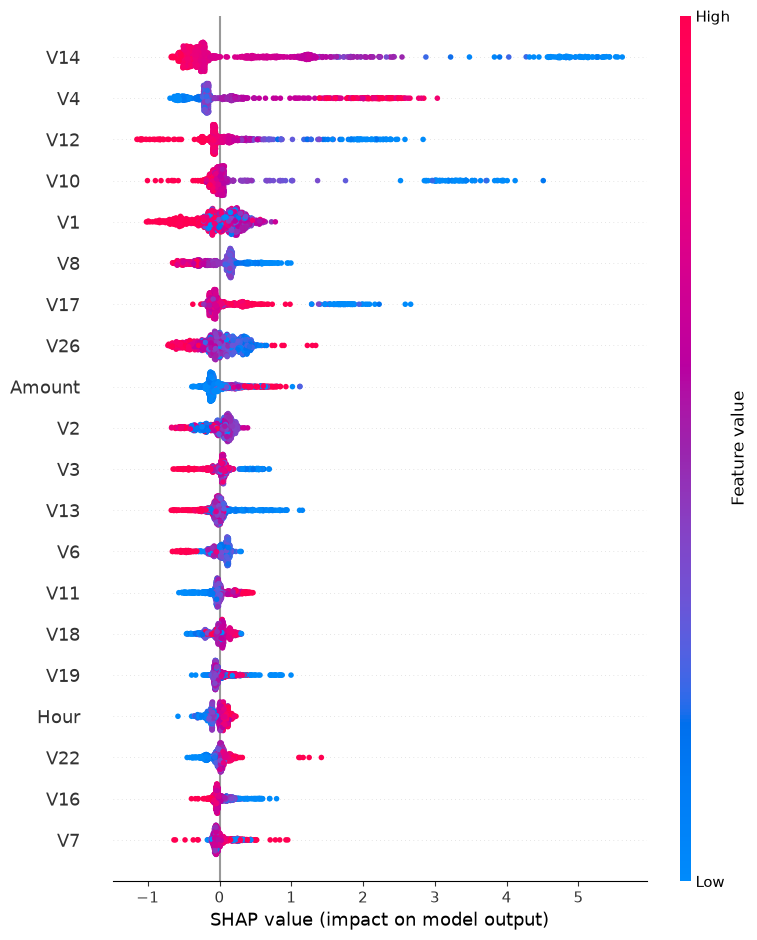

In [19]:
import shap
import pandas as pd
import matplotlib.pyplot as plt

# All test frauds + a sample of normal transactions (frauds are too rare for a random sample)
X_explain = pd.concat([
    X_test[y_test == 1],
    X_test[y_test == 0].sample(1000, random_state=42),
])

explainer = shap.TreeExplainer(cat)
shap_values = explainer.shap_values(X_explain)

shap.summary_plot(shap_values, X_explain, show=False)
plt.savefig("../reports/figures/shap_summary.png", bbox_inches="tight", dpi=130)
plt.show()

Fraud probability: 0.966


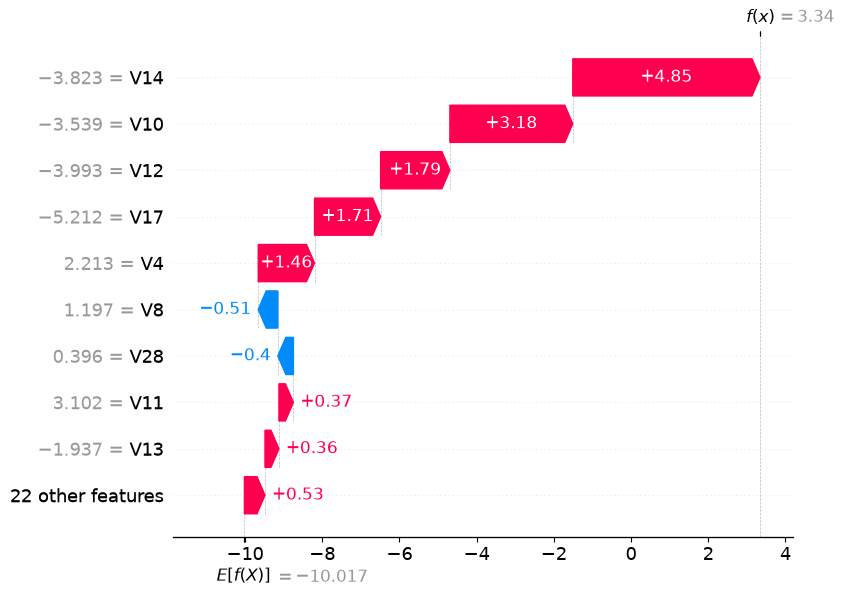

In [20]:
import numpy as np

proba = cat.predict_proba(X_test)[:, 1]
caught = np.where((y_test.to_numpy() == 1) & (proba >= best_t))[0]

row = X_test.iloc[[caught[0]]]            # first fraud the model caught
print("Fraud probability:", round(cat.predict_proba(row)[0, 1], 3))

explanation = explainer(row)
shap.plots.waterfall(explanation[0], show=False)
plt.savefig("../reports/figures/shap_waterfall.png", bbox_inches="tight", dpi=130)
plt.show()

In [21]:
import json
from pathlib import Path

Path("../models").mkdir(exist_ok=True)

# 1. The trained model
cat.save_model("../models/catboost_fraud.cbm")

# 2. Everything the API needs to use it correctly
meta = {
    "threshold": float(best_t),
    "features": list(X_train.columns),
    "cost_fn": COST_FN,
    "cost_fp": COST_FP,
    "test_pr_auc": 0.8265,
}
with open("../models/model_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print(meta)

{'threshold': 0.11, 'features': ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Hour'], 'cost_fn': 120, 'cost_fp': 5, 'test_pr_auc': 0.8265}


In [23]:
import pandas as pd
from sklearn.model_selection import cross_val_score

def cv_score(cols, name):
    scores = cross_val_score(cat, X_train[cols], y_train, cv=cv, scoring="average_precision")
    print(f"{name}: PR-AUC = {scores.mean():.3f} ± {scores.std():.3f}  ({len(cols)} features)")

all_cols = list(X_train.columns)

# 1. Drop Hour
cv_score([c for c in all_cols if c != "Hour"], "without Hour")

# 2. Keep only the most important features (importance computed on TRAINING data)
imp = pd.Series(cat.get_feature_importance(), index=X_train.columns).sort_values(ascending=False)
print(imp.head(10))

for k in [10, 15, 25]:
    cv_score(list(imp.index[:k]), f"top {k}")

without Hour: PR-AUC = 0.849 ± 0.028  (30 features)
V1        10.169107
V14        8.800996
V4         6.926178
V26        6.006796
V13        5.563361
Amount     4.382671
V2         4.368993
V8         3.822791
V12        3.555603
V11        3.323049
dtype: float64
top 10: PR-AUC = 0.827 ± 0.032  (10 features)
top 15: PR-AUC = 0.838 ± 0.034  (15 features)
top 25: PR-AUC = 0.849 ± 0.028  (25 features)


In [24]:
import json
from pathlib import Path

Path("../models").mkdir(exist_ok=True)

cat.save_model("../models/catboost_fraud.cbm")

meta = {
    "threshold": float(best_t),
    "features": list(X_train.columns),
    "cost_fn": COST_FN,
    "cost_fp": COST_FP,
    "test_pr_auc": 0.8265,
}
with open("../models/model_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print(meta)

{'threshold': 0.11, 'features': ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Hour'], 'cost_fn': 120, 'cost_fp': 5, 'test_pr_auc': 0.8265}


In [25]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from catboost import CatBoostClassifier
from sklearn.model_selection import cross_val_score

def make_cat(**kw):
    return CatBoostClassifier(iterations=300, learning_rate=0.1, depth=6,
                              eval_metric="PRAUC", random_seed=42,
                              thread_count=-1, verbose=0, **kw)

# 1. Class weights
cat_w = make_cat(auto_class_weights="Balanced")

# 2. SMOTE, inside the pipeline so it only touches training folds
cat_smote = ImbPipeline([
    ("smote", SMOTE(sampling_strategy=0.1, random_state=42)),
    ("model", make_cat()),
])

for name, model in {"CatBoost weights": cat_w, "CatBoost SMOTE": cat_smote}.items():
    s = cross_val_score(model, X_train, y_train, cv=cv, scoring="average_precision")
    print(f"{name}: PR-AUC = {s.mean():.3f} ± {s.std():.3f}")

CatBoost weights: PR-AUC = 0.834 ± 0.036
CatBoost SMOTE: PR-AUC = 0.852 ± 0.038


In [30]:
from fraudshield.prediction import predict_transaction

fraud_idx = y_test[y_test == 1].index[0]       # a real fraud from the test set
sample = X_test.loc[fraud_idx].to_dict()

print(predict_transaction(sample))
print("Notebook probability:", round(cat.predict_proba(X_test.loc[[fraud_idx]])[0, 1], 4))

sample.pop("Hour")                              # the function must rebuild Hour itself
print(predict_transaction(sample))

{'fraud_probability': 0.9658, 'is_fraud': True, 'threshold': 0.11}
Notebook probability: 0.9658
{'fraud_probability': 0.9658, 'is_fraud': True, 'threshold': 0.11}


In [33]:
import json
with open("../sample_transaction.json", "w") as f:
    json.dump(sample, f, indent=2)